# Predictive Integrity Risk Assessment of FPSO Pipelines
Uncertainty-Aware Degradation Modelling using PRDS Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

In [3]:
df = pd.read_excel("PRDS_files/PRDS_Merged_Docs_Normalized.xlsx")
df.head()

,filename,date,prdsNumber,lineLocation,lineId,nominalPipeSize,originalWallThickness,pipeSchedule,pipeMaterial,pipeGrade,...,Product,axialLength,circumferentialWidth,damageLocation,remainingWallThickness,corrosionPercentage,internalCorrosionRate,isLeaking,temporaryRepair,additionalNotes
0,PRDS_1534_24-CM-A2-138-031,2023-06-08,PRDS_1534,M5P,24-CM-A2-138-031,"20""",9.53,STD,carbon steel,A106 GR-B,...,Seawater,900.0,400.0,external,2.8,70.6,NaN,0.0,1.0,Significant localized material loss on the pip...
1,PRDS_TR01628_03-UW-M-004-106,2023-12-02,PRDS_1628,KNK- module 5P,03-UW-M-004-106,"2""",5.54,XS,carbon steel,NaN,...,RO Water,NaN,NaN,internal,0.0,NaN,NaN,1.0,0.0,Internal corrosion noted on seam at flange con...
2,PRDS_TR01503_04-DC-B2-10501-002,2023-05-07,PRDS_1503,MV21 - M2P,04-DC-B2-10501-002,"4""",6.02,40,carbon steel,ASTM A106 GR B,...,Closed Drain - HC,80.0,50.0,external,1.0,NaN,NaN,0.0,0.0,NaN
3,PRDS_TR01515_04-DC-B2-10501-005,2023-05-13,PRDS_1515,MV21 - M2P,04-DC-B2-10501-005,"4""",6.02,40,carbon steel,ASTM A106 GR B,...,Closed Drain - HC,NaN,NaN,external,1.1,NaN,NaN,0.0,0.0,NaN
4,PRDS_1546_02-DC-A2-137-002,2023-06-24,PRDS_1546,Module 5S,02-DC-A2-137-002,"2""",5.54,NaN,carbon steel,NaN,...,Closed Drain - HC,60.0,60.0,external,1.4,NaN,NaN,0.0,0.0,NO scales to be removed during repair


# Visualising the Data 

<Axes: xlabel='Product'>

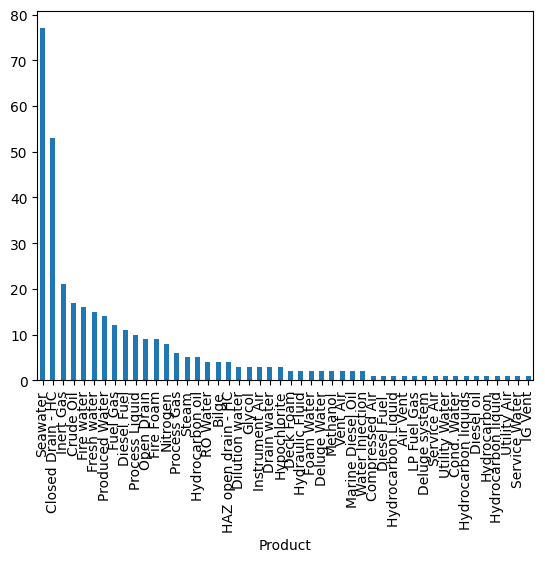

In [9]:
df['Product'].value_counts().plot(kind='bar')

## Feature Engineering

In [4]:
df['date'] = pd.to_datetime(df['date'])
df['Exposure_Years'] = df['date'].dt.year - 2010
df = df[df['Exposure_Years'] > 0] #remove invalid

In [5]:
df['Corrosion_Rate'] = (
    df['originalWallThickness'] - df['remainingWallThickness']
) / df['Exposure_Years']

In [6]:
CRITICAL_THICKNESS = 1.0
df['RUL'] = (
    df['remainingWallThickness'] - CRITICAL_THICKNESS
) / df['Corrosion_Rate']

In [7]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=['Corrosion_Rate', 'RUL'])

## Visualisation

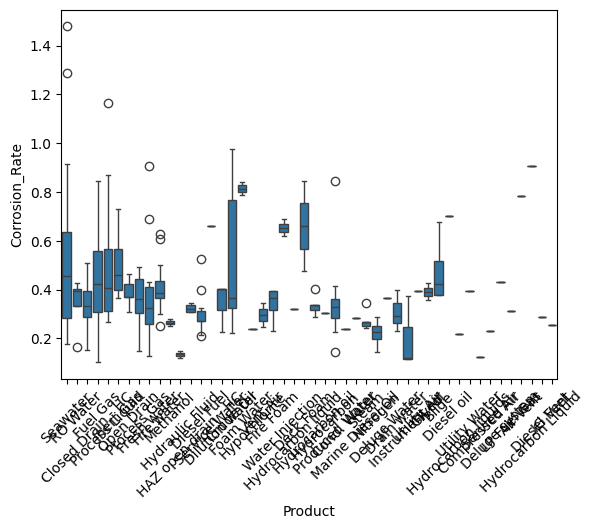

In [8]:
plt.figure()
sns.boxplot(x='Product', y='Corrosion_Rate', data=df)
plt.xticks(rotation=45)
plt.show()

In [ ]:
plt.figure()
sns.boxplot(x='Product', y='RUL', data=df)
plt.xticks(rotation=45)
plt.show()

## Modeling

In [ ]:
df = pd.get_dummies(df, columns=['Product'], drop_first=True)
features = ['Exposure_Years','maxOperatingTemperature','maxOperatingPressure'] + [col for col in df.columns if 'Product_' in col]
X = df[features]

In [ ]:
model_rul = RandomForestRegressor(n_estimators=200)
model_rul.fit(X, df['RUL'])
df['Pred_RUL'] = model_rul.predict(X)

## Uncertainty

In [ ]:
preds = []
for i in range(20):
    m = RandomForestRegressor(n_estimators=100)
    m.fit(X, df['RUL'])
    preds.append(m.predict(X))

preds = np.array(preds)
df['RUL_std'] = preds.std(axis=0)
df['Confidence'] = 1 / (1 + df['RUL_std'])

## Risk Score

In [ ]:
df['Risk_Score'] = (1 / df['Pred_RUL']) * df['RUL_std']

In [ ]:
plt.figure()
sns.boxplot(x='Product', y='Risk_Score', data=df)
plt.xticks(rotation=45)
plt.show()